In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('indian_liver_patient.csv')
print(df.shape)
print(df.head())

(583, 11)
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
0   65  Female              0.7               0.1                   187   
1   62    Male             10.9               5.5                   699   
2   62    Male              7.3               4.1                   490   
3   58    Male              1.0               0.4                   182   
4   72    Male              3.9               2.0                   195   

   Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Protiens  \
0                        16                          18             6.8   
1                        64                         100             7.5   
2                        60                          68             7.0   
3                        14                          20             6.8   
4                        27                          59             7.3   

   Albumin  Albumin_and_Globulin_Ratio  Dataset  
0      3.3                        0.90

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


In [ ]:
print(df.isnull().sum())
print(df.duplicated().sum())
print(df['Dataset'].value_counts())

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Dataset                       0
dtype: int64
13
Dataset
1    416
2    167
Name: count, dtype: int64


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['Liver_Disease'] = df['Dataset'].map({1: 1, 2: 0})
df = df.drop(columns='Dataset')
print(df.shape)

(570, 11)


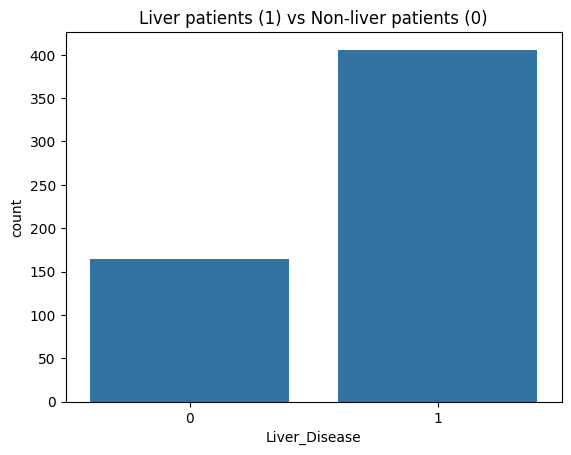

In [ ]:
sns.countplot(x='Liver_Disease', data=df)
plt.title("Liver patients (1) vs Non-liver patients (0)")
plt.show()

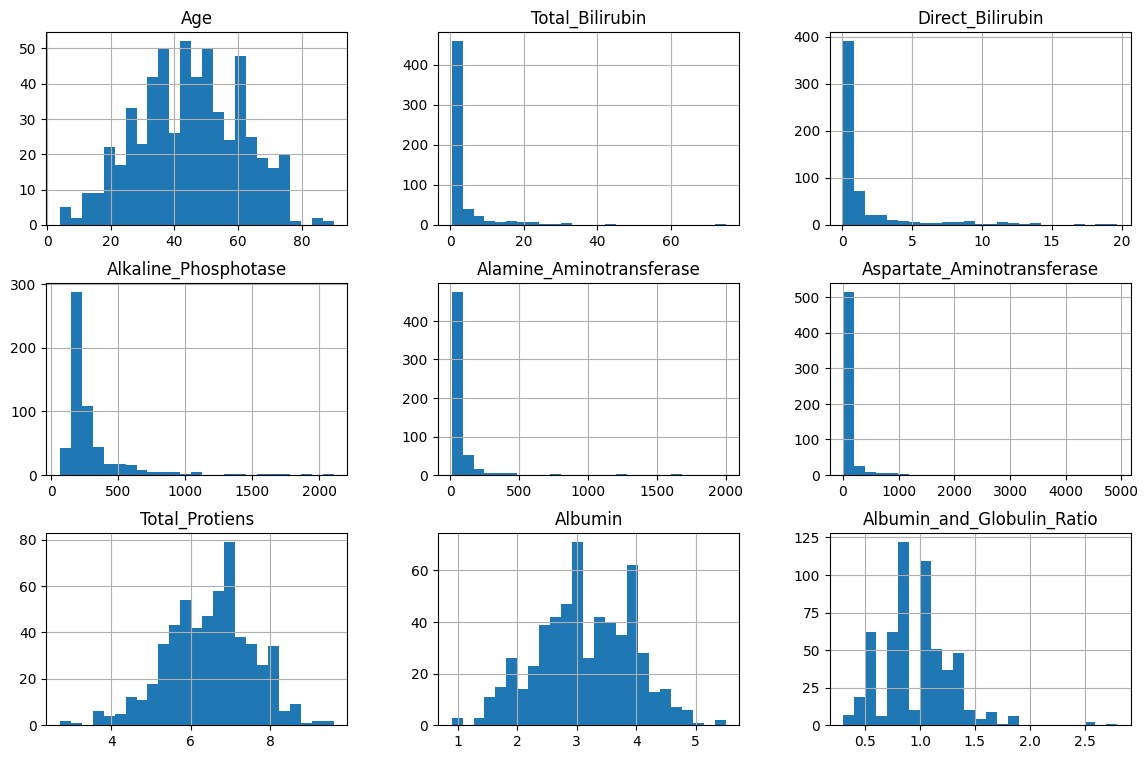

In [ ]:
num_cols = ['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase',
            'Alamine_Aminotransferase', 'Aspartate_Aminotransferase',
            'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']

df[num_cols].hist(bins=25, figsize=(14, 9))
plt.show()

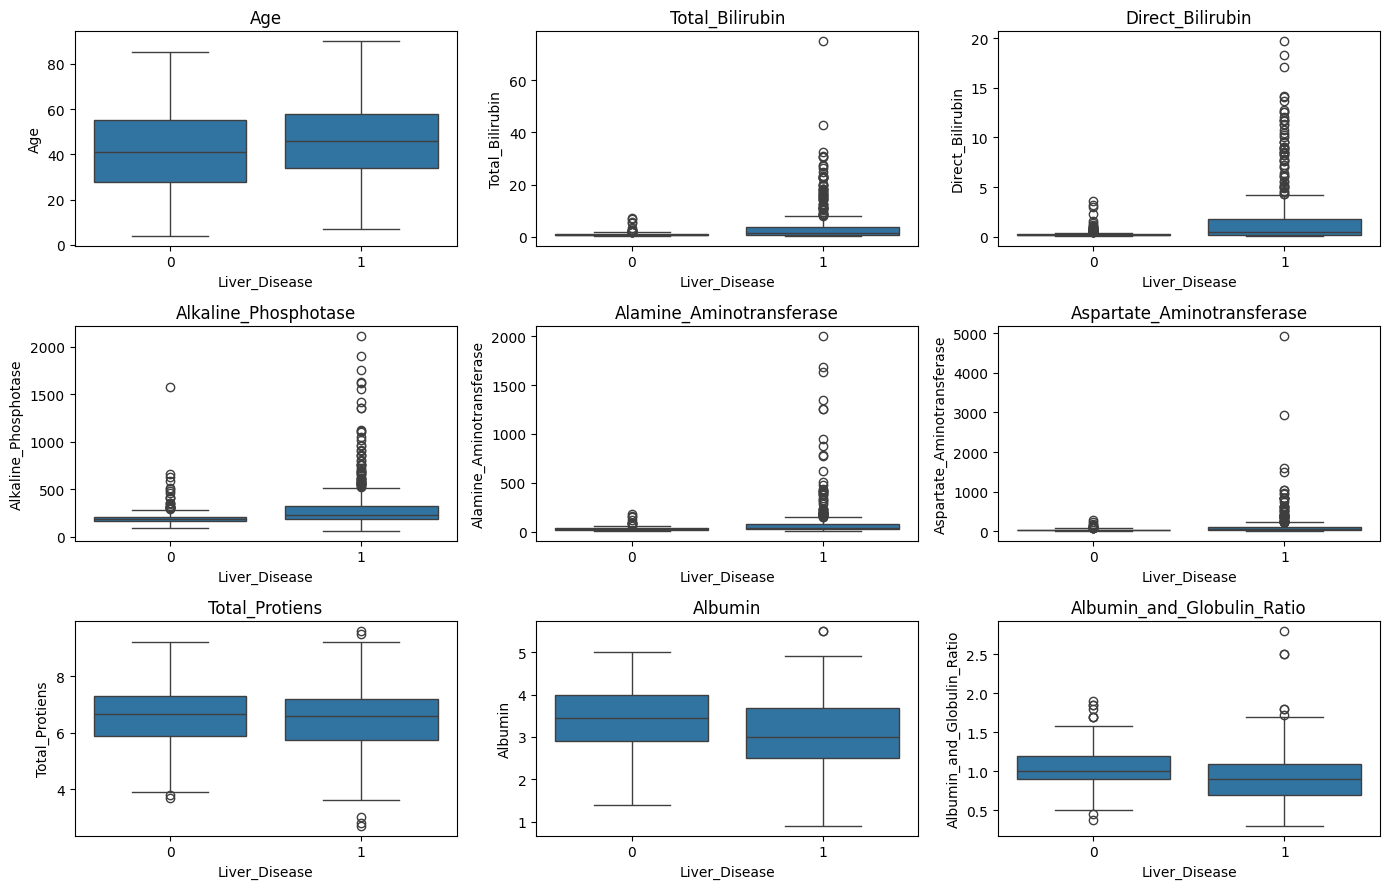

In [ ]:
plt.figure(figsize=(14, 9))
for i, col in enumerate(num_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(x='Liver_Disease', y=col, data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

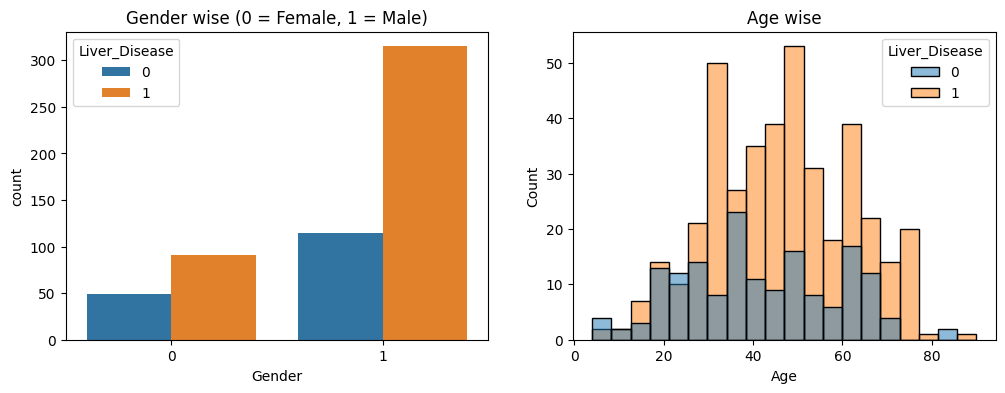

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(x='Gender', hue='Liver_Disease', data=df)
plt.title("Gender wise (0 = Female, 1 = Male)")
plt.subplot(1, 2, 2)
sns.histplot(data=df, x='Age', hue='Liver_Disease', bins=20)
plt.title("Age wise")
plt.show()

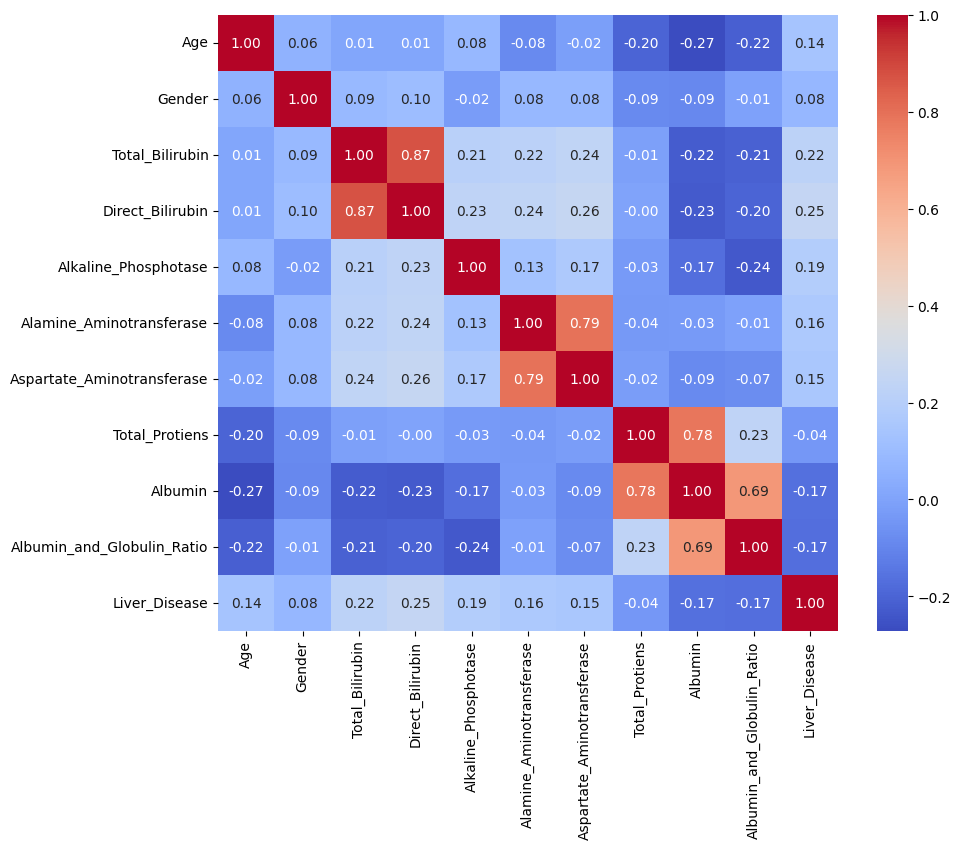

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [ ]:
X = df.drop(columns='Liver_Disease')
Y = df['Liver_Disease']

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size = 0.2, stratify = Y, random_state = 42
)
median_value = X_train['Albumin_and_Globulin_Ratio'].median()
X_train['Albumin_and_Globulin_Ratio'] = X_train['Albumin_and_Globulin_Ratio'].fillna(median_value)
X_test['Albumin_and_Globulin_Ratio'] = X_test['Albumin_and_Globulin_Ratio'].fillna(median_value)
print(X_train.shape, X_test.shape)

(456, 10) (114, 10)


In [ ]:
print(Y_train.value_counts())
smote = SMOTE(random_state = 42)
X_train_sm, Y_train_sm = smote.fit_resample(X_train, Y_train)
print(Y_train_sm.value_counts())

Liver_Disease
1    325
0    131
Name: count, dtype: int64
Liver_Disease
1    325
0    325
Name: count, dtype: int64


In [ ]:
dt_model = DecisionTreeClassifier(random_state = 42)
dt_model.fit(X_train_sm, Y_train_sm)

rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42)
rf_model.fit(X_train_sm, Y_train_sm)

nb_model = GaussianNB()
nb_model.fit(X_train_sm, Y_train_sm)

GaussianNB()

In [ ]:
models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Naive Bayes": nb_model
}

results = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append([name,
                    accuracy_score(Y_test, pred),
                    precision_score(Y_test, pred),
                    recall_score(Y_test, pred),
                    f1_score(Y_test, pred),
                    roc_auc_score(Y_test, prob)])

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])
results_df = results_df.round(3)
print(results_df)

           Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Decision Tree     0.702       0.77   0.827     0.798    0.611
1  Random Forest     0.737       0.78   0.877     0.826    0.772
2    Naive Bayes     0.623       1.00   0.469     0.639    0.805


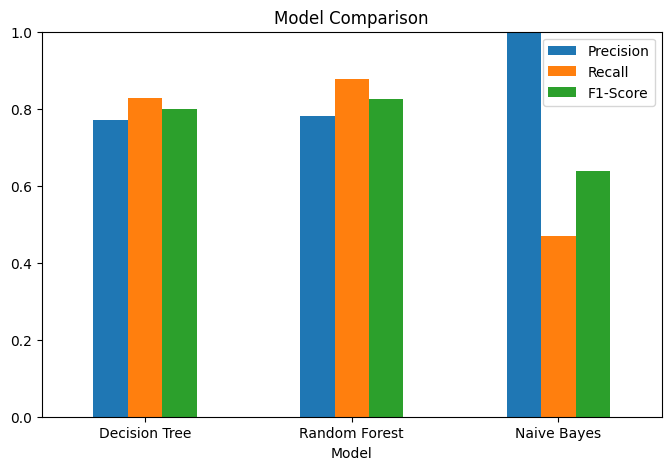

In [ ]:
results_df.set_index("Model")[["Precision", "Recall", "F1-Score"]].plot(kind="bar", figsize=(8, 5))
plt.title("Model Comparison")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

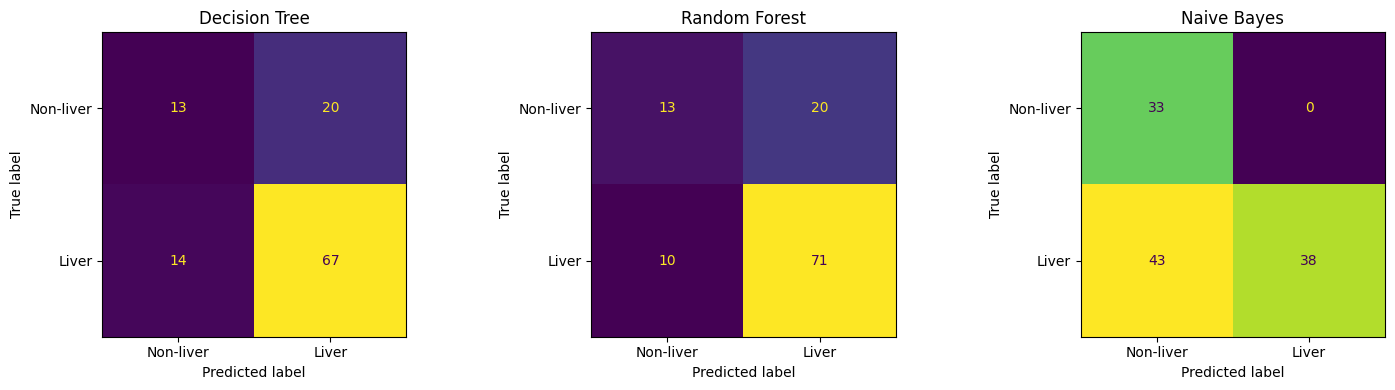

In [ ]:
plt.figure(figsize=(15, 4))
for i, (name, model) in enumerate(models.items()):
    plt.subplot(1, 3, i + 1)
    cm = confusion_matrix(Y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Non-liver", "Liver"]).plot(ax=plt.gca(), colorbar=False)
    plt.title(name)
plt.tight_layout()
plt.show()

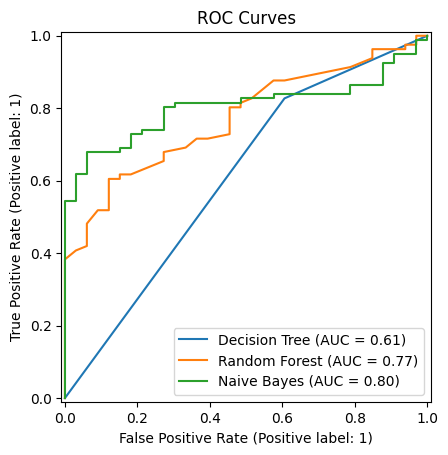

In [ ]:
ax = plt.gca()
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, Y_test, ax=ax, name=name)
plt.title("ROC Curves")
plt.show()

In [ ]:
for name, m in [("Decision Tree", DecisionTreeClassifier(random_state = 42)),
                ("Random Forest", RandomForestClassifier(random_state = 42)),
                ("Naive Bayes", GaussianNB())]:
    pipe = make_pipeline(SMOTE(random_state = 42), m)
    scores = cross_val_score(pipe, X_train, Y_train, cv = 5, scoring = "f1")
    print(name, "CV F1 :", scores.mean().round(3))

Decision Tree CV F1 : 0.752
Random Forest CV F1 : 0.753
Naive Bayes CV F1 : 0.522


In [ ]:
rf_pipe = make_pipeline(SMOTE(random_state = 42), RandomForestClassifier(random_state = 42))

rf_params = {
    "randomforestclassifier__n_estimators": [100, 200],
    "randomforestclassifier__max_depth": [None, 5, 10],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5]
}

rf_grid = GridSearchCV(rf_pipe, rf_params, cv = 5, scoring = "f1")
rf_grid.fit(X_train, Y_train)
print("Best parameters :", rf_grid.best_params_)
print("Best CV F1 :", round(rf_grid.best_score_, 3))

Best parameters : {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 3, 'randomforestclassifier__n_estimators': 200}
Best CV F1 : 0.755


In [ ]:
tuned = rf_grid.best_estimator_
pred = tuned.predict(X_test)
prob = tuned.predict_proba(X_test)[:, 1]

tuned_row = pd.DataFrame([["Random Forest (Tuned)",
                           accuracy_score(Y_test, pred),
                           precision_score(Y_test, pred),
                           recall_score(Y_test, pred),
                           f1_score(Y_test, pred),
                           roc_auc_score(Y_test, prob)]], columns=results_df.columns).round(3)

final_df = pd.concat([results_df, tuned_row], ignore_index=True)
print(final_df)

                   Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0          Decision Tree     0.702       0.77   0.827     0.798    0.611
1          Random Forest     0.737       0.78   0.877     0.826    0.772
2            Naive Bayes     0.623       1.00   0.469     0.639    0.805
3  Random Forest (Tuned)     0.693       0.78   0.790     0.785    0.788


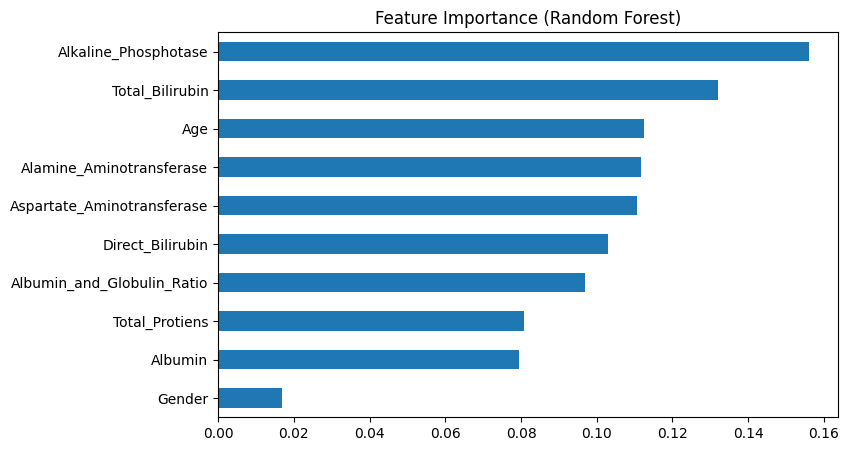

In [ ]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance (Random Forest)")
plt.show()

In [ ]:
print(final_df.loc[final_df["F1-Score"].idxmax()])

Model        Random Forest
Accuracy             0.737
Precision             0.78
Recall               0.877
F1-Score             0.826
ROC-AUC              0.772
Name: 1, dtype: object
